# Superstore Sales Analysis: Python EDA

Reusable data-cleaning pipeline plus exploratory analysis of the Superstore orders dataset (9,994 order lines).

**Pipeline:** load → inspect → handle missing values → cap outliers (IQR) → engineer features → optimise memory → KPI summary.
**Analysis:** 10 business questions answered with charts and written insights.

> **Note:** Totals, KPIs and rankings use the *uncapped* data (`df_full`). The outlier-capped data (`df`) is used only where outliers would distort the picture (correlation matrix, profit box plot).


# Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)


# Loading Dataset

In [2]:
def load_dataset(filepath, sheet_name=0):
    if filepath.endswith('.csv'):
        return pd.read_csv(filepath)
    return pd.read_excel(filepath, sheet_name=sheet_name)

# Inspect Dataset

In [3]:
def inspect_dataset(df):
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Data Types:\n{df.dtypes}")
    print(f"Missing Values:\n{df.isnull().sum()}")
    print(f"Memory Usage (MB): {round(df.memory_usage(deep=True).sum() / 1024**2, 2)}")
    display(df.head())

# Handling missing values 
based on a column-mapping dictionary

In [4]:
def handle_missing_values(df, impute_dict=None):
    df_clean = df.copy()
    cols_to_drop = [c for c in ['Unnamed: 0', 'Row ID'] if c in df_clean.columns]
    if cols_to_drop:
        df_clean = df_clean.drop(columns=cols_to_drop)
    if impute_dict:
        for col, val in impute_dict.items():
            if col in df_clean.columns:
                df_clean[col] = df_clean[col].fillna(val)
    return df_clean

# Handling outliers

In [5]:
def handle_outliers_iqr(df, columns, factor=1.5, method='cap'):
    df_clean = df.copy()
    
    for col in columns:
        if col in df_clean.columns:
            Q1 = df_clean[col].quantile(0.25)
            Q3 = df_clean[col].quantile(0.75)
            IQR = Q3 - Q1
            
            lower_bound = Q1 - (factor * IQR)
            upper_bound = Q3 + (factor * IQR)
            
            if method == 'cap':
                df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)
            elif method == 'remove':
                # Filtering out rows outside boundaries
                df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
                
    return df_clean

# Feature engineering
1. converting date columns to datetime 
2. calculating shipping duration ,profit margin ratio
3. Extracting individual time parts from the full order date timestamp
4. Splitting continuous sales numbers into 3 equal-volume categorical

In [6]:
def engineer_features(df, start_date_col, end_date_col, sales_col, profit_col):
    df_feat = df.copy()
    
    # Date Conversions
    df_feat[start_date_col] = pd.to_datetime(df_feat[start_date_col])
    df_feat[end_date_col] = pd.to_datetime(df_feat[end_date_col])
    
    # Feature Engineering
    df_feat["Shipping Duration"] = (df_feat[end_date_col] - df_feat[start_date_col]).dt.days
    df_feat["Profit Margin"] = (df_feat[profit_col] / df_feat[sales_col]).replace([np.inf, -np.inf], np.nan).fillna(0)
    df_feat["Order Month"] = df_feat[start_date_col].dt.month
    df_feat["Order Year"] = df_feat[start_date_col].dt.year
    df_feat["YearMonth"] = df_feat[start_date_col].dt.to_period("M")
    
    # Binned Sales Performance Tiers
    q33, q66 = df_feat[sales_col].quantile(0.33), df_feat[sales_col].quantile(0.66)
    df_feat["Sales Category"] = pd.cut(df_feat[sales_col], bins=[-np.inf, q33, q66, np.inf], labels=["Low", "Medium", "High"])
    
    return df_feat

# Optimize Memory

In [7]:
def optimize_memory(df, categorical_cols):
    df_opt = df.copy()
    
    # Convert string categories to category dtype
    for col in categorical_cols:
        if col in df_opt.columns:
            df_opt[col] = df_opt[col].astype("category")
            
    # Downcast numerics
    for col in df_opt.select_dtypes(include=['float64']).columns:
        df_opt[col] = pd.to_numeric(df_opt[col], downcast='float')
    for col in df_opt.select_dtypes(include=['int64']).columns:
        df_opt[col] = pd.to_numeric(df_opt[col], downcast='integer')
        
    return df_opt

# KPI summary

In [8]:
def build_kpi_summary(df, sales_col, profit_col, order_id_col, qty_col, duration_col):
    return pd.DataFrame({
        "Metric": ["Total Revenue", "Total Profit", "Overall Profit Margin", "Total Orders", "Units Sold", "Avg Shipping Time"],
        "Value": [
            f"${df[sales_col].sum():,.2f}",
            f"${df[profit_col].sum():,.2f}",
            f"{(df[profit_col].sum() / df[sales_col].sum()) * 100:.2f}%",
            f"{df[order_id_col].nunique():,}",
            f"{df[qty_col].sum():,}",
            f"{df[duration_col].mean():.1f} Days"
        ]
    })

# Data Pipeline Execution

In [9]:
# Place the dataset in the data/ folder (see data/README.md)
file_path = 'data/Sample - Superstore 2019.xls'
sheet_name = "Orders"

df_raw = load_dataset(file_path, sheet_name=sheet_name)

inspect_dataset(df_raw)

df_filled = handle_missing_values(df_raw, impute_dict={"Postal Code": 5401})

df_no_outliers = handle_outliers_iqr(df_filled, columns=["Sales", "Profit"], method='cap')
df_engineered = engineer_features(
    df_no_outliers, 
    start_date_col="Order Date", 
    end_date_col="Ship Date", 
    sales_col="Sales", 
    profit_col="Profit"
)

# `df` = outlier-capped data (used for distribution-sensitive plots)
df = optimize_memory(
    df_engineered, 
    categorical_cols=["Ship Mode", "Segment", "Region", "Category", "Sub-Category", "Sales Category"]
)

print(f"Final Shape: {df.shape} | Memory: {df.memory_usage().sum() / 1024**2:.2f} MB")
# `df_full` = same features, NO outlier capping (used for totals, KPIs and rankings,
# because capping Sales/Profit would understate revenue and profit)
df_full = optimize_memory(
    engineer_features(df_filled, start_date_col="Order Date", end_date_col="Ship Date",
                      sales_col="Sales", profit_col="Profit"),
    categorical_cols=["Ship Mode", "Segment", "Region", "Category", "Sub-Category", "Sales Category"]
)


Shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Data Types:
Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State                        str
Postal Code              float64
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
d

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Final Shape: (9994, 26) | Memory: 1.18 MB


# Summary Statistics & Executive KPIs

In [10]:
num_cols = ["Sales", "Profit", "Quantity", "Discount", "Shipping Duration", "Profit Margin"]

print("Summary Statistics for Numeric Columns:")
display(df_full[num_cols].describe().round(2))

# KPIs
kpis = build_kpi_summary(df_full, "Sales", "Profit", "Order ID", "Quantity", "Shipping Duration")
display(kpis)

Summary Statistics for Numeric Columns:


,Sales,Profit,Quantity,Discount,Shipping Duration,Profit Margin
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,28.66,3.79,0.16,3.96,0.12
std,623.25,234.26,2.23,0.21,1.75,0.47
min,0.44,-6599.98,1.00,0.00,0.00,-2.75
25%,17.28,1.73,2.00,0.00,3.00,0.08
50%,54.49,8.67,3.00,0.20,4.00,0.27
75%,209.94,29.36,5.00,0.20,5.00,0.36
max,22638.48,8399.98,14.00,0.80,7.00,0.50


,Metric,Value
0,Total Revenue,"$2,297,200.86"
1,Total Profit,"$286,397.03"
2,Overall Profit Margin,12.47%
3,Total Orders,"5,009"
4,Units Sold,"37,873"
5,Avg Shipping Time,4.0 Days


# Q1: What are the primary metrics correlated with Profit and Sales?

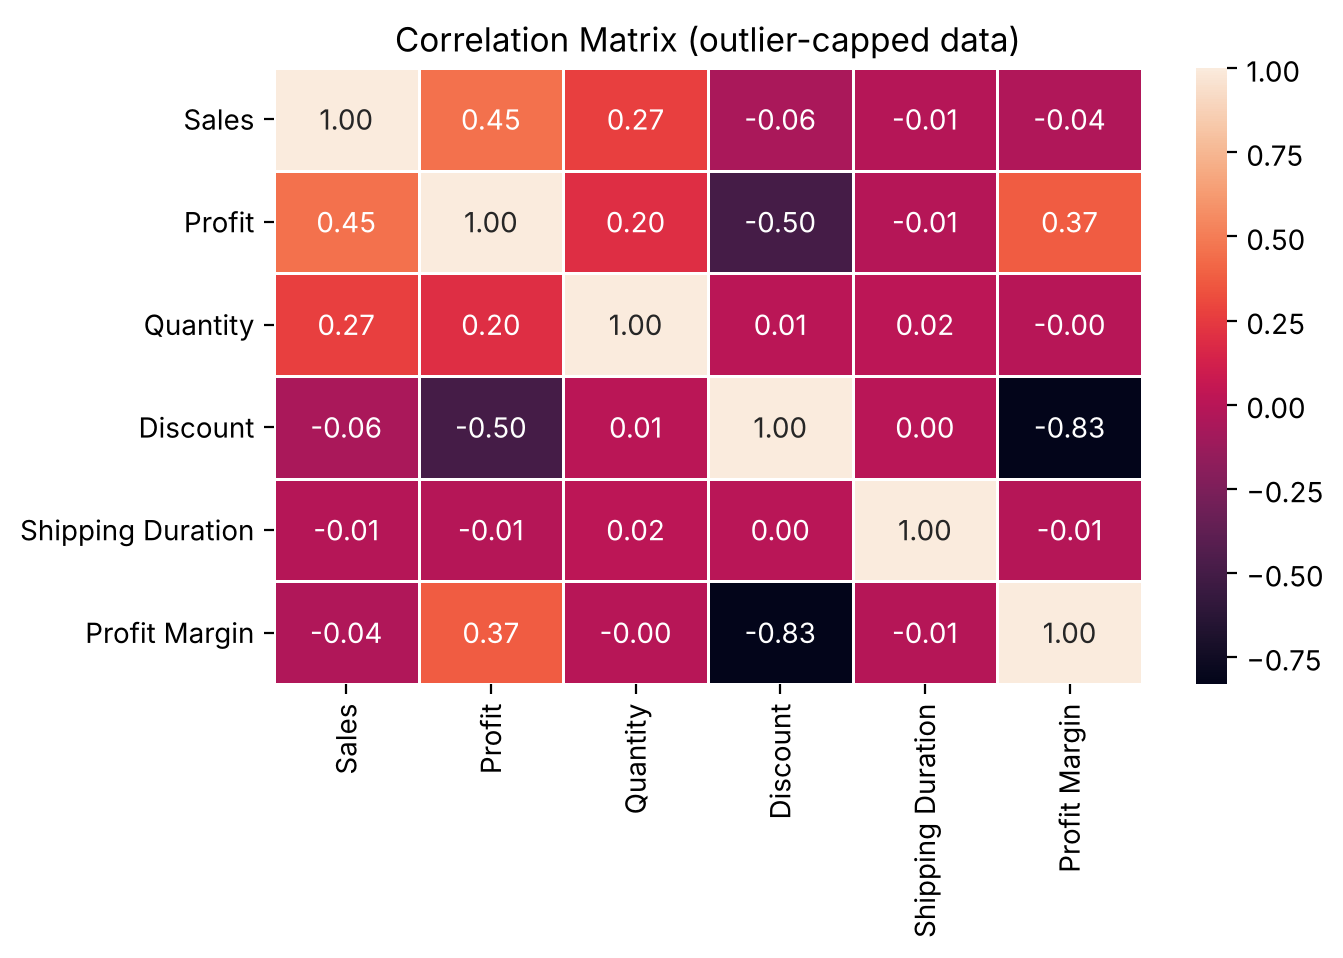

In [11]:
plt.figure(figsize=(7, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="rocket", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix (outlier-capped data)")
plt.show()

**Key Insights:**

* *Discount* and *profit* are **negatively** correlated (**-0.50**): heavier discounting goes with lower profit per order. It isn't the only factor, since sales also matters (**0.45** with profit).
* *Discount* has a strong negative correlation with *profit margin* (**-0.83**), the strongest relationship in the matrix.


# Q2: What is the monthly sales revenue trend over time?

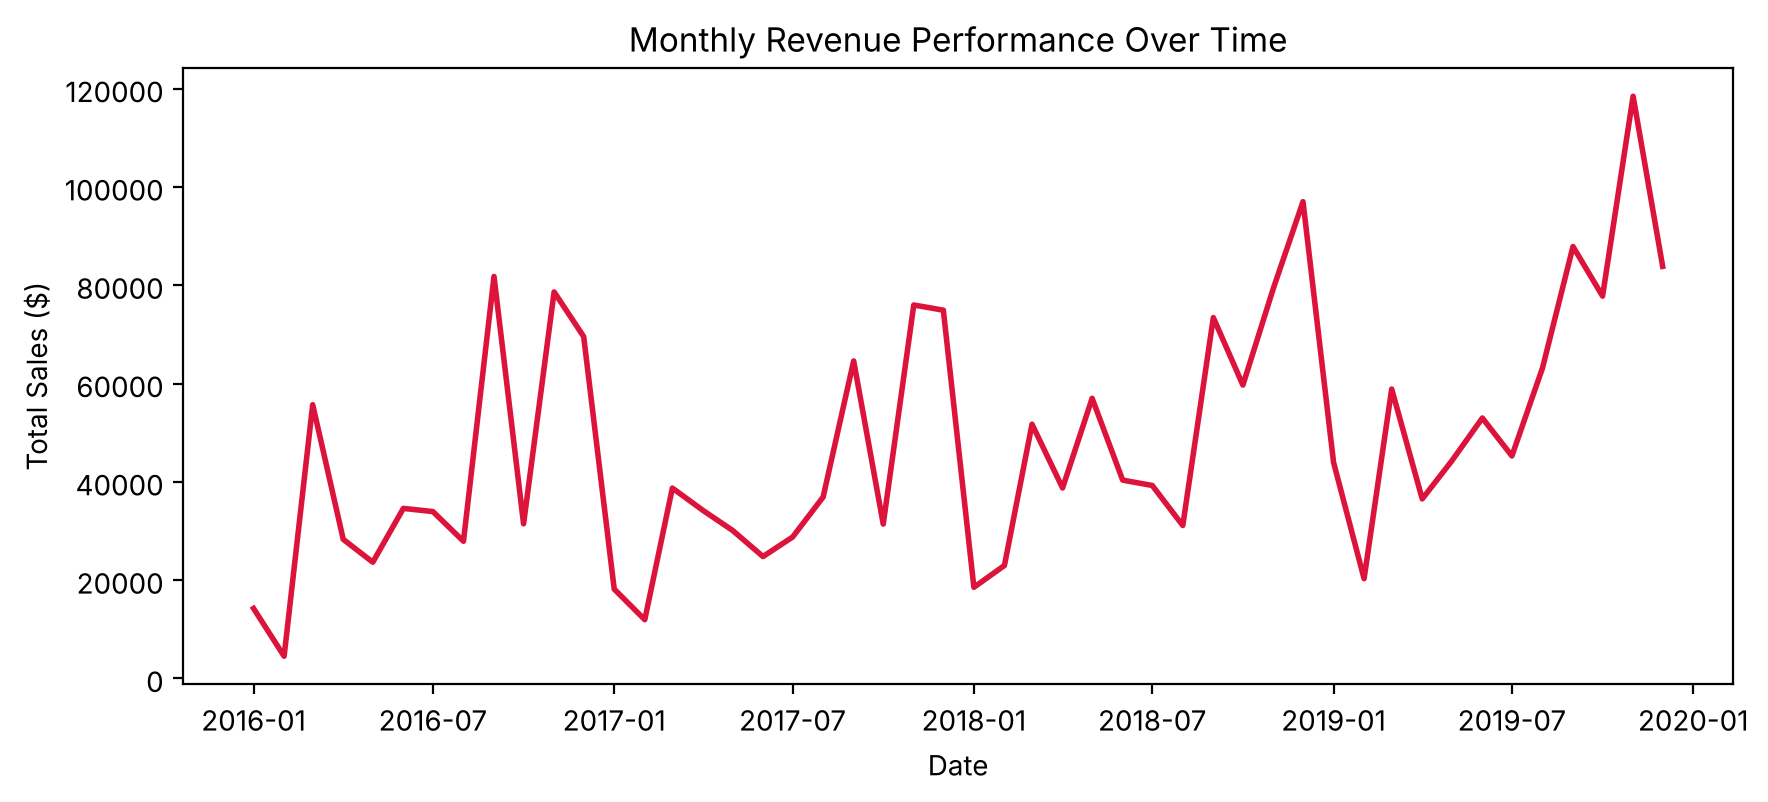

In [12]:
plt.figure(figsize=(10, 4))
monthly_sales = df_full.groupby("YearMonth")["Sales"].sum().reset_index()
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].dt.to_timestamp()
sns.lineplot(data=monthly_sales, x="YearMonth", y="Sales", color="crimson", linewidth=2)
plt.title("Monthly Revenue Performance Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales ($)")
plt.show()

**Key Insights:**
* **Growth with a dip:** Annual sales fell slightly in 2017 ($471K vs $484K in 2016), then grew to $609K in 2018 and $733K in 2019 (+51% vs 2016). The best month was November 2019 (~$118K).
* **Strong Q4 seasonality:** September to December account for about half of annual sales (Nov ≈ 15%, Dec ≈ 14%, Sep ≈ 13%).
* **Weak Q1:** January (≈ 4%) and February (≈ 3%) are the slowest months, so inventory and marketing spend should scale up from Q3 and down in early Q1.


# Q3: Which Product Categories generate the highest revenue and profit?

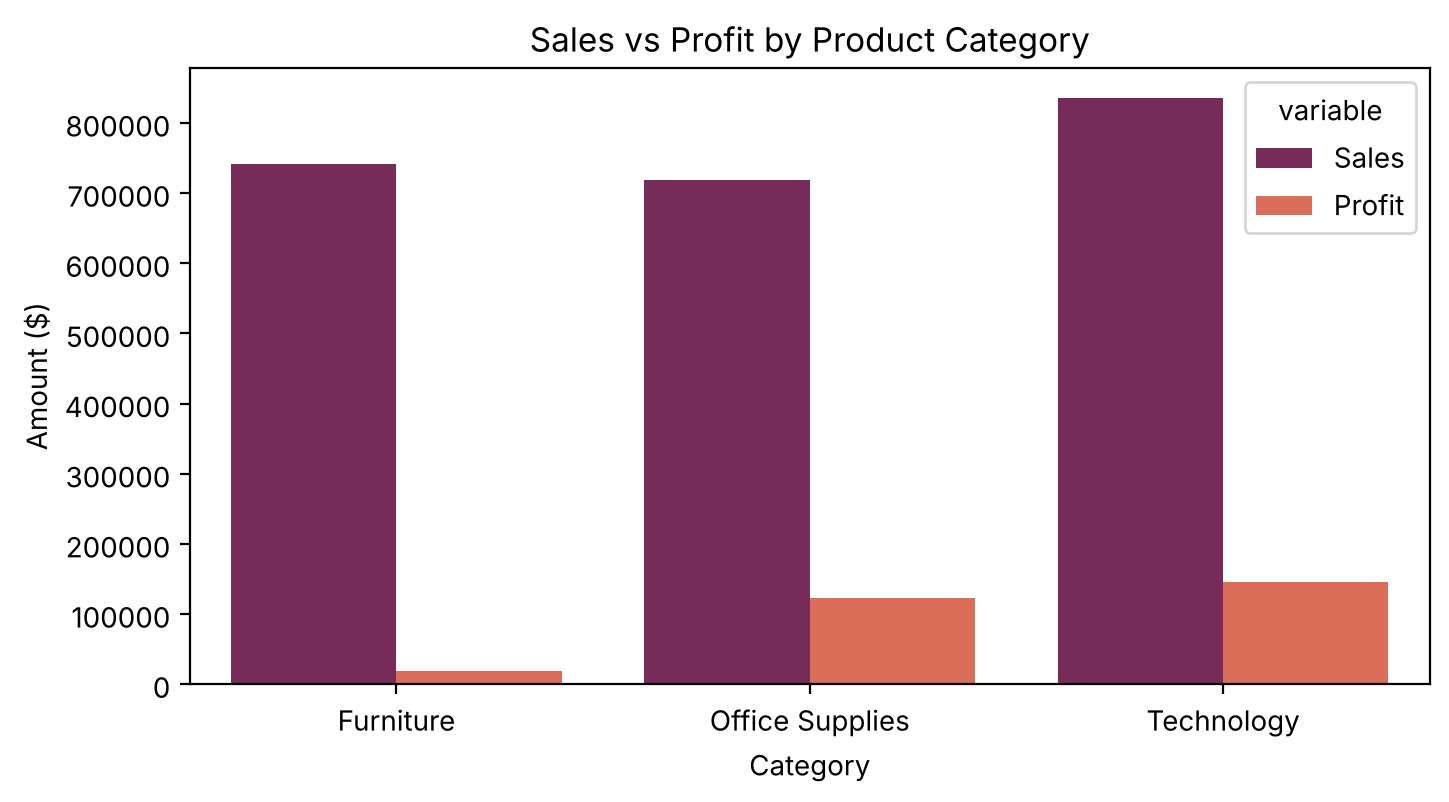

In [13]:
plt.figure(figsize=(8, 4))
cat_perf = df_full.groupby("Category")[["Sales", "Profit"]].sum().reset_index().melt(id_vars="Category")
sns.barplot(data=cat_perf, x="Category", y="value", hue="variable", palette="rocket")
plt.title("Sales vs Profit by Product Category")
plt.ylabel("Amount ($)")
plt.show()

**Key Insights:**
* **Technology** has the highest revenue ($836K) and the highest profit ($145K).
* **Office Supplies** is close behind on profit ($122K) with lower revenue ($719K).
* **Furniture** earns about as much revenue as Office Supplies ($742K) but only $18K profit (≈ 2.5% margin), so it is the category to investigate.


# Q4: How is profitability distributed across Customer Segments?

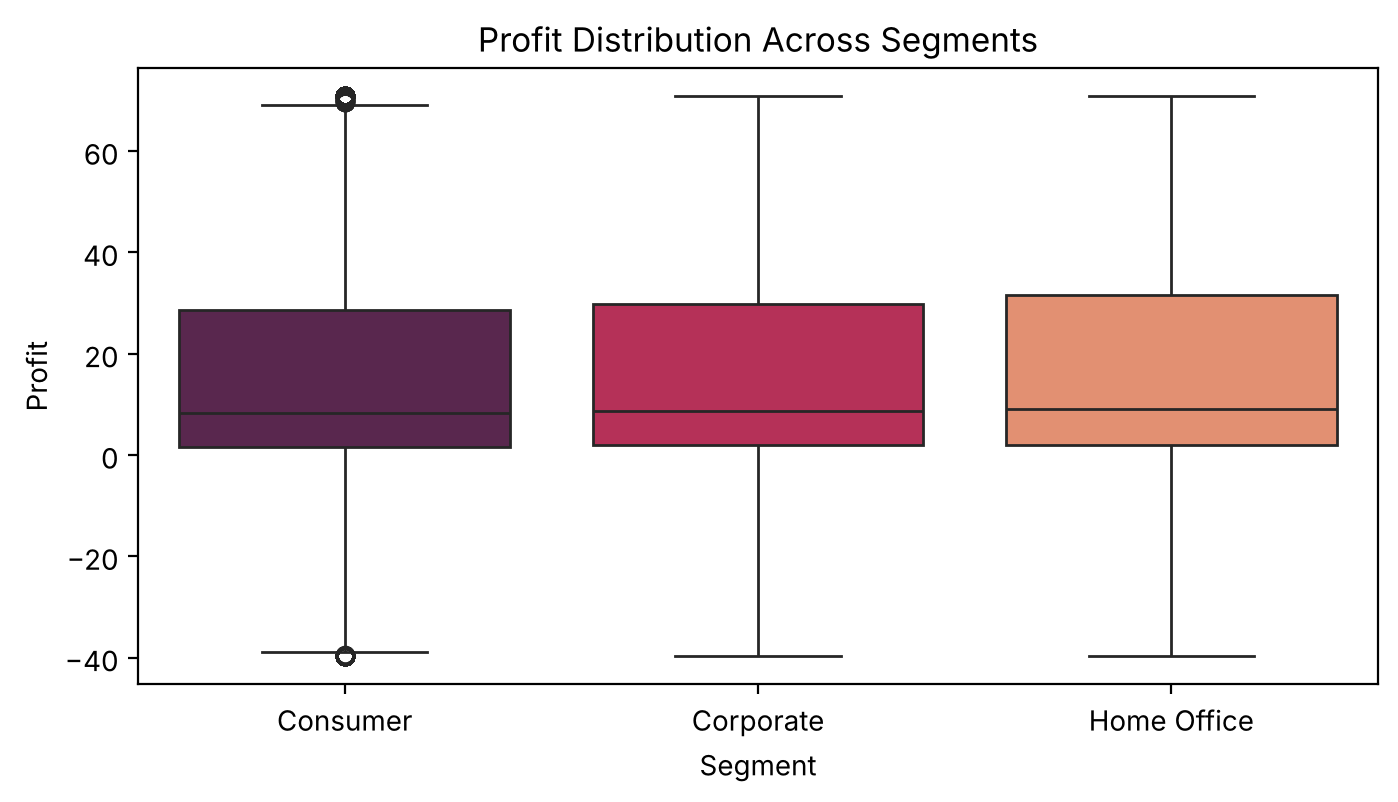

In [14]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Segment", y="Profit", palette="rocket")
plt.title("Profit Distribution Across Segments")
plt.show()

**Key Insights:**
* **Similar median profit:** Median profit per order line is nearly identical across Consumer, Corporate and Home Office (about $8–9), so baseline pricing looks consistent.
* **Loss risk is not segment-specific:** Loss-making order lines appear in all three segments, which points to discounting and product margins rather than customer type. (Plot uses outlier-capped data.)
* Consumer is still the biggest segment by revenue ($1.16M vs $706K Corporate and $430K Home Office).


# Q5: How does Shipping Duration vary by Ship Mode?

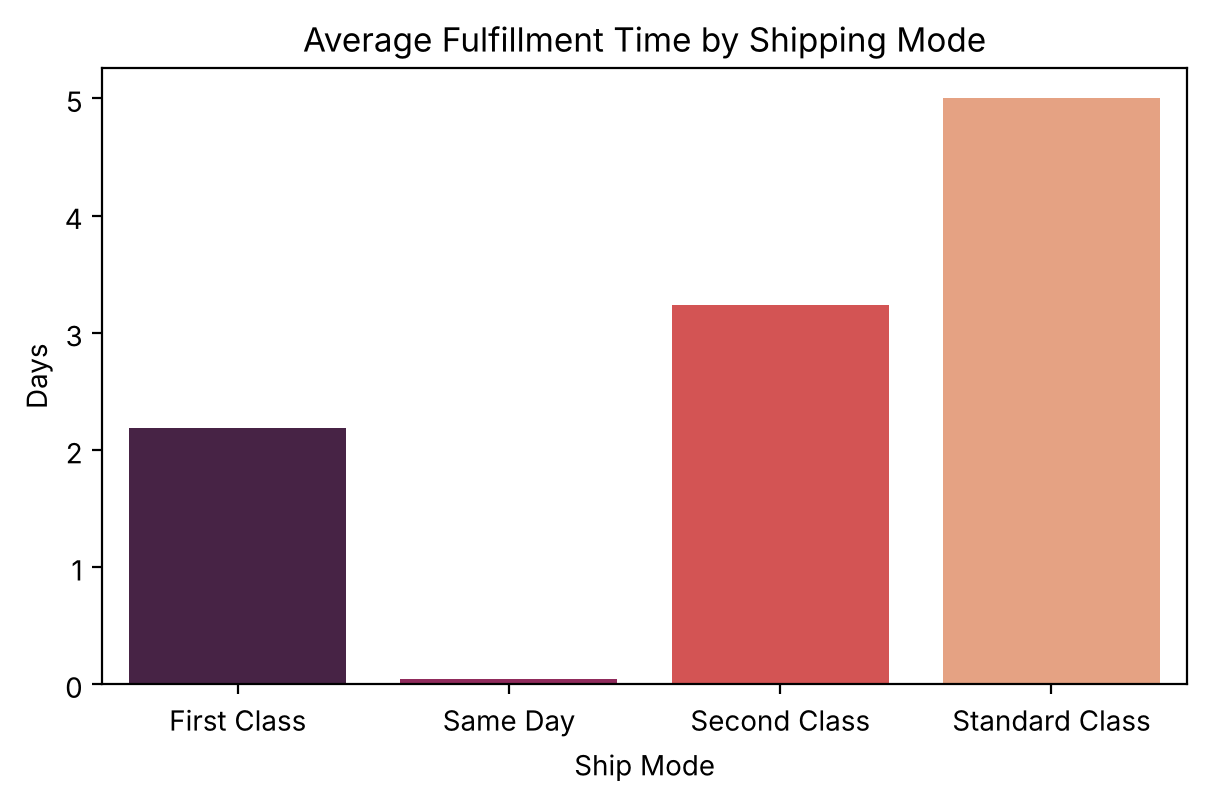

In [15]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df_full, x="Ship Mode", y="Shipping Duration", palette="rocket", errorbar=None)
plt.title("Average Fulfillment Time by Shipping Mode")
plt.ylabel("Days")
plt.show()

**Key Insights:**
* **Same Day** is the fastest mode, averaging about 0 days.
* **First Class** averages ~2.2 days, **Second Class** ~3.2 days and **Standard Class** is the slowest at ~5 days.


# Q6: How are order volumes distributed across low, medium, and high sales tiers?

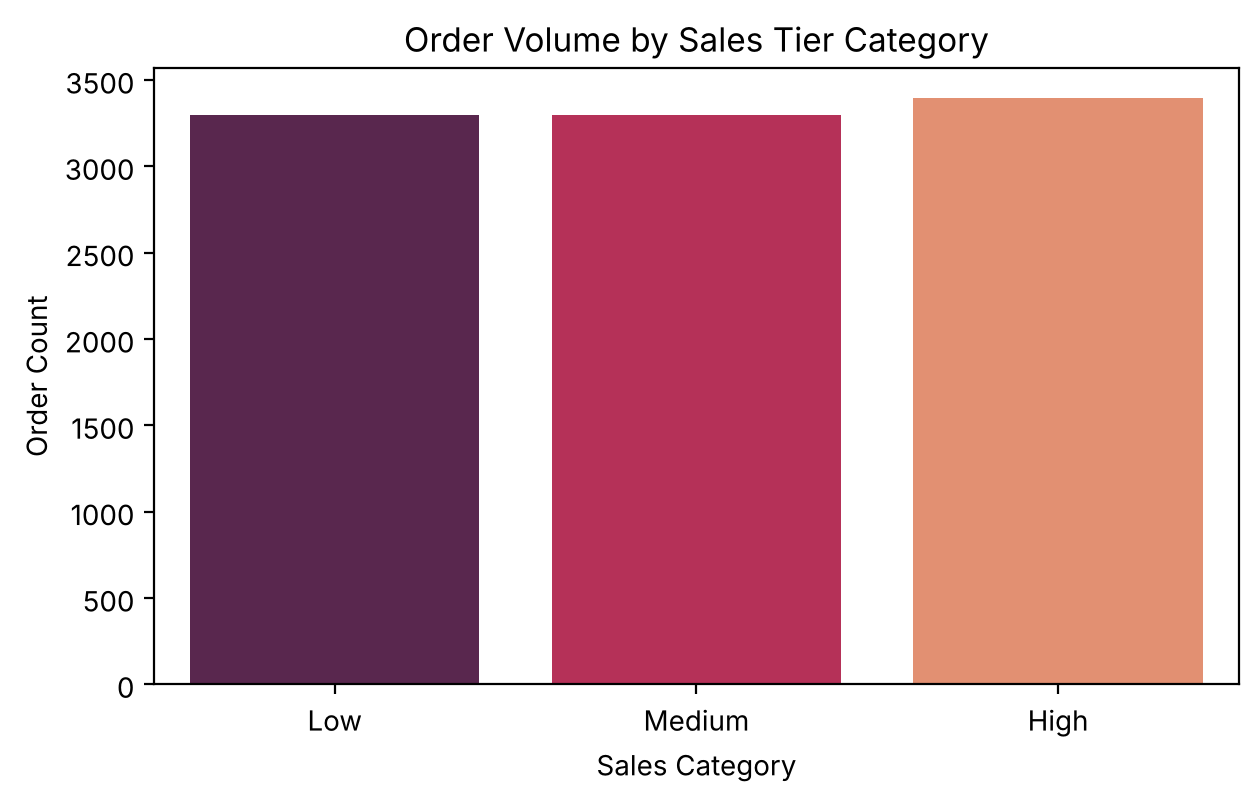

In [16]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_full, x="Sales Category", palette="rocket")
plt.title("Order Volume by Sales Tier Category")
plt.ylabel("Order Count")
plt.show()

**Key Insights:**
* Order volume is almost uniformly distributed across the three tiers (expected, since the tiers are built from sales terciles).


# Q7: What is the impact of Discount rates on Profitability?

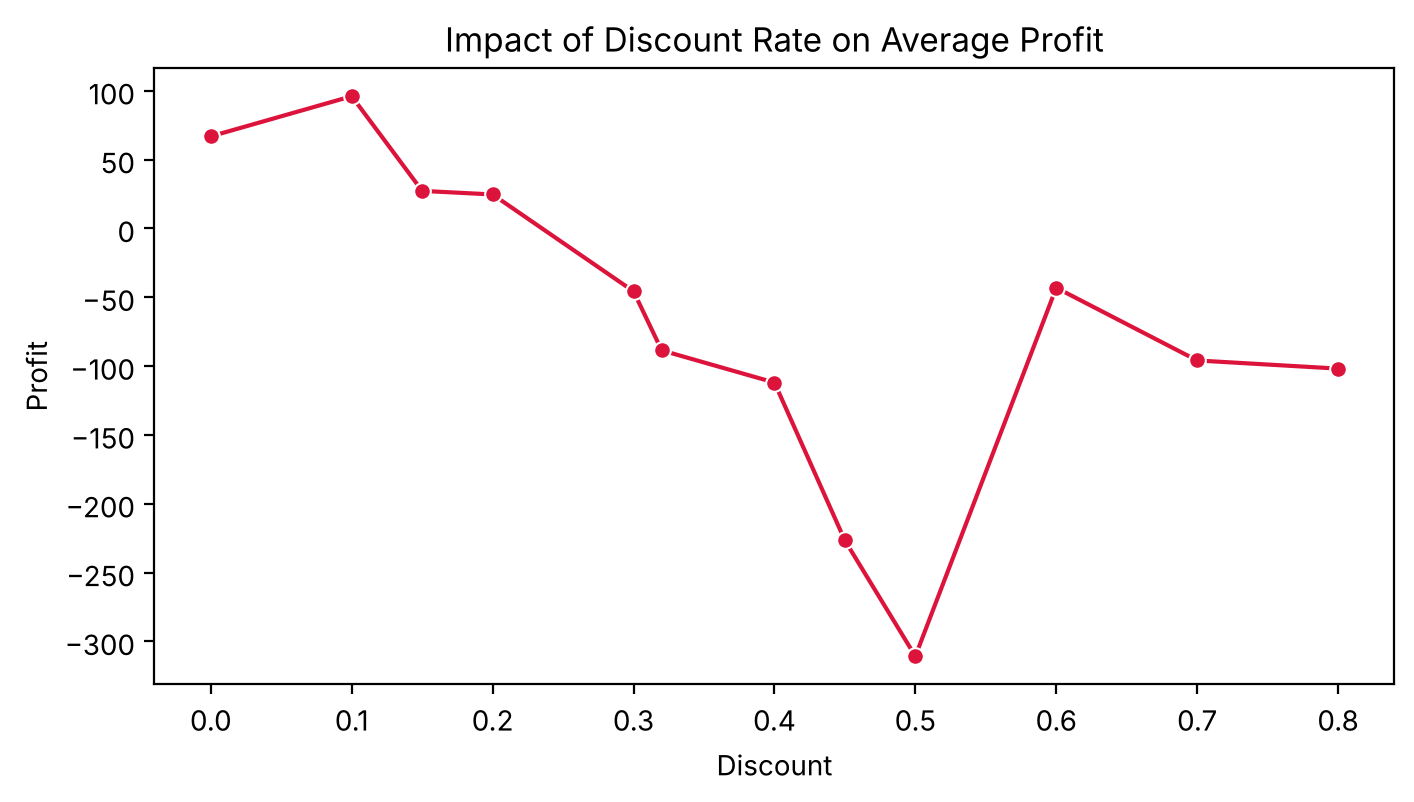

In [17]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=df_full, x="Discount", y="Profit", color="crimson", errorbar=None, marker="o")
plt.title("Impact of Discount Rate on Average Profit")
plt.show()

**Key Insights:**
* Average profit per order line peaks at a **10% discount** (~$96) and stays positive up to 20% (~$25).
* From **30% upward** the average order line loses money, with the worst losses around 45–50% (about -$230 to -$310 per line).
* **Recommendation:** cap discounts at 20% and require managerial approval above that.


# Q8: Which top 10 States drive the majority of sales revenue?

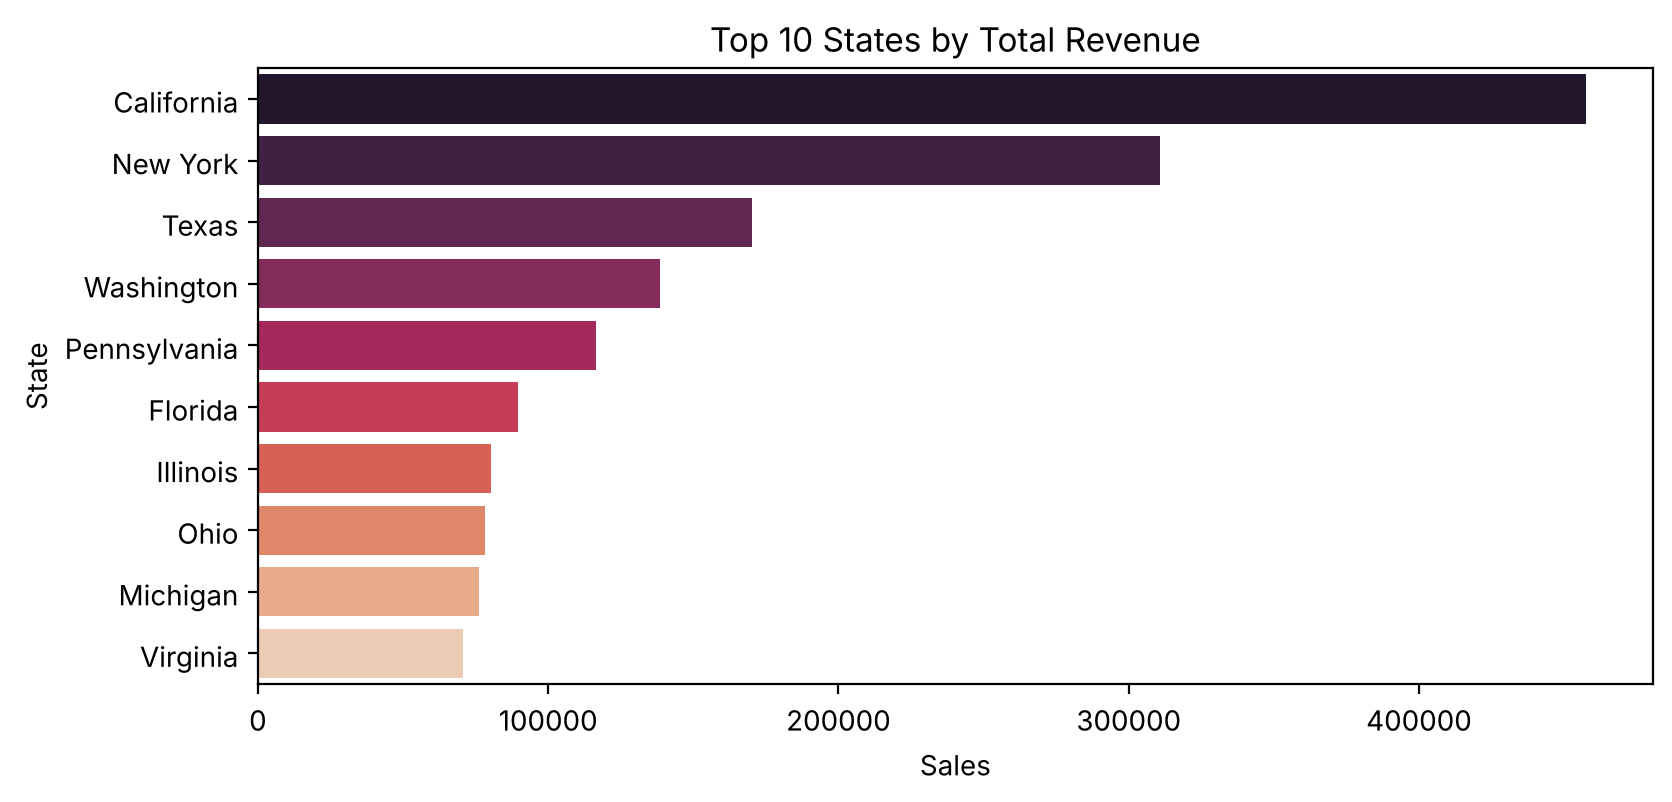

In [18]:
plt.figure(figsize=(9, 4))
top_states = df_full.groupby("State")["Sales"].sum().nlargest(10).reset_index()
sns.barplot(data=top_states, x="Sales", y="State", palette="rocket")
plt.title("Top 10 States by Total Revenue")
plt.show()

**Key Insights:**
* **California** is the top state with about $458K in revenue.
* **New York** is second with about $311K.
* **Texas** is third (~$170K) and every other state is below $140K, so California and New York deserve the most attention.


# Q9: Which Sub-Categories generate the lowest profit (or highest losses)?

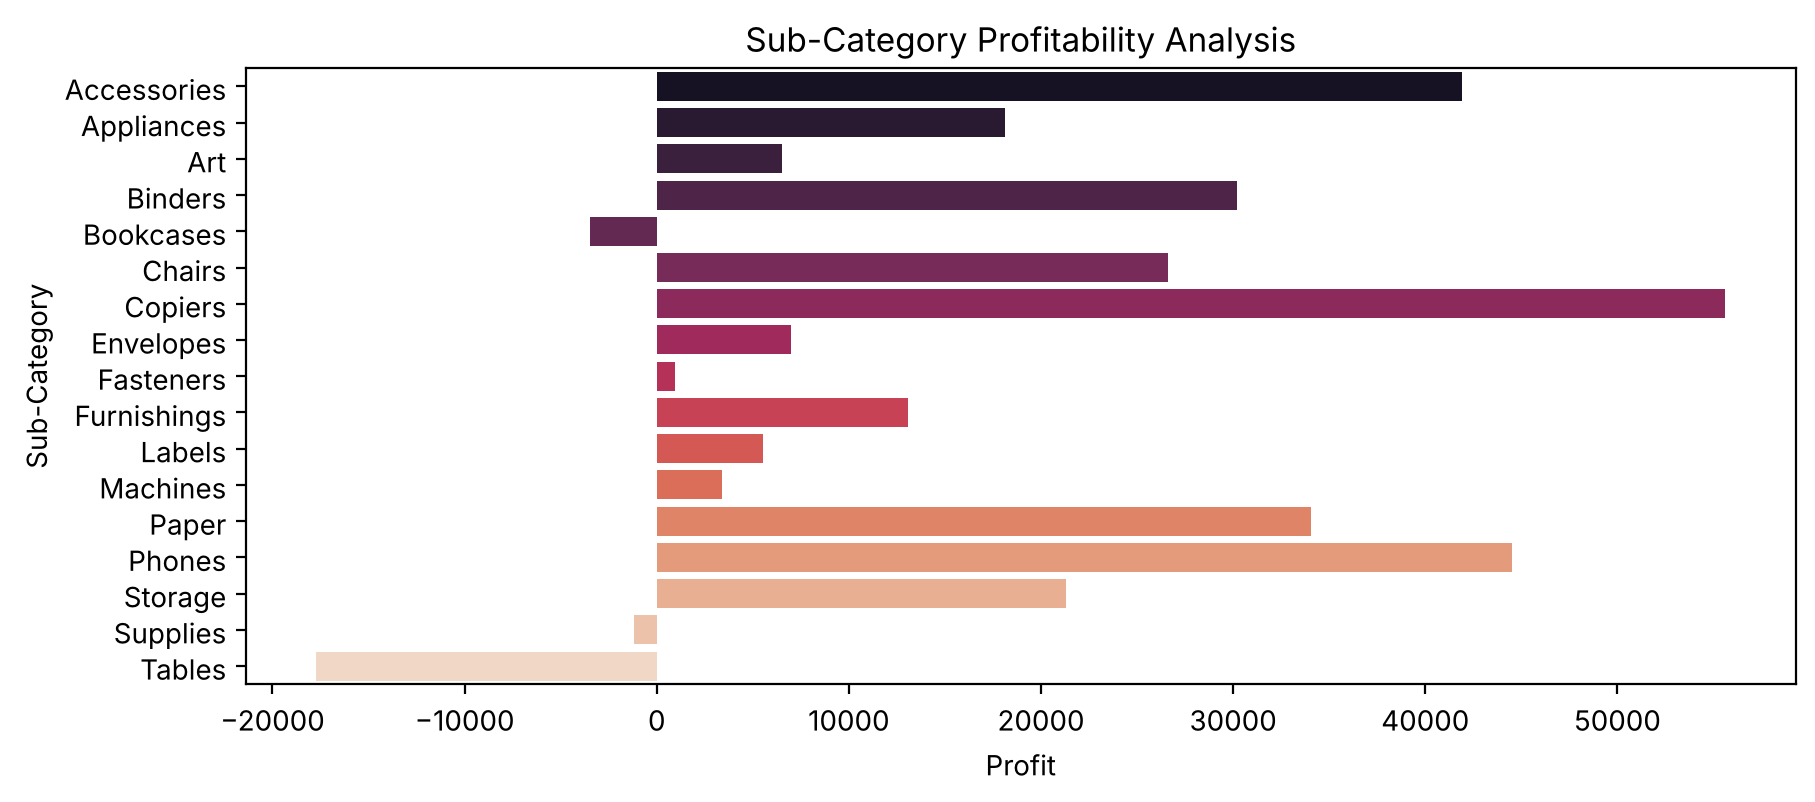

In [19]:
plt.figure(figsize=(10, 4))
subcat_profit = df_full.groupby("Sub-Category")["Profit"].sum().sort_values().reset_index()
sns.barplot(data=subcat_profit, x="Profit", y="Sub-Category", palette="rocket")
plt.title("Sub-Category Profitability Analysis")
plt.show()

**Key Insights:**
* **Copiers, Phones, Accessories and Paper** are the most profitable sub-categories (Copiers ≈ $56K).
* **Tables** (-$17.7K), **Bookcases** (-$3.5K) and **Supplies** (-$1.2K) are the only loss-making sub-categories. Tables is by far the biggest problem.


# Q10: What is the average Profit Margin percentage by Regional Market?

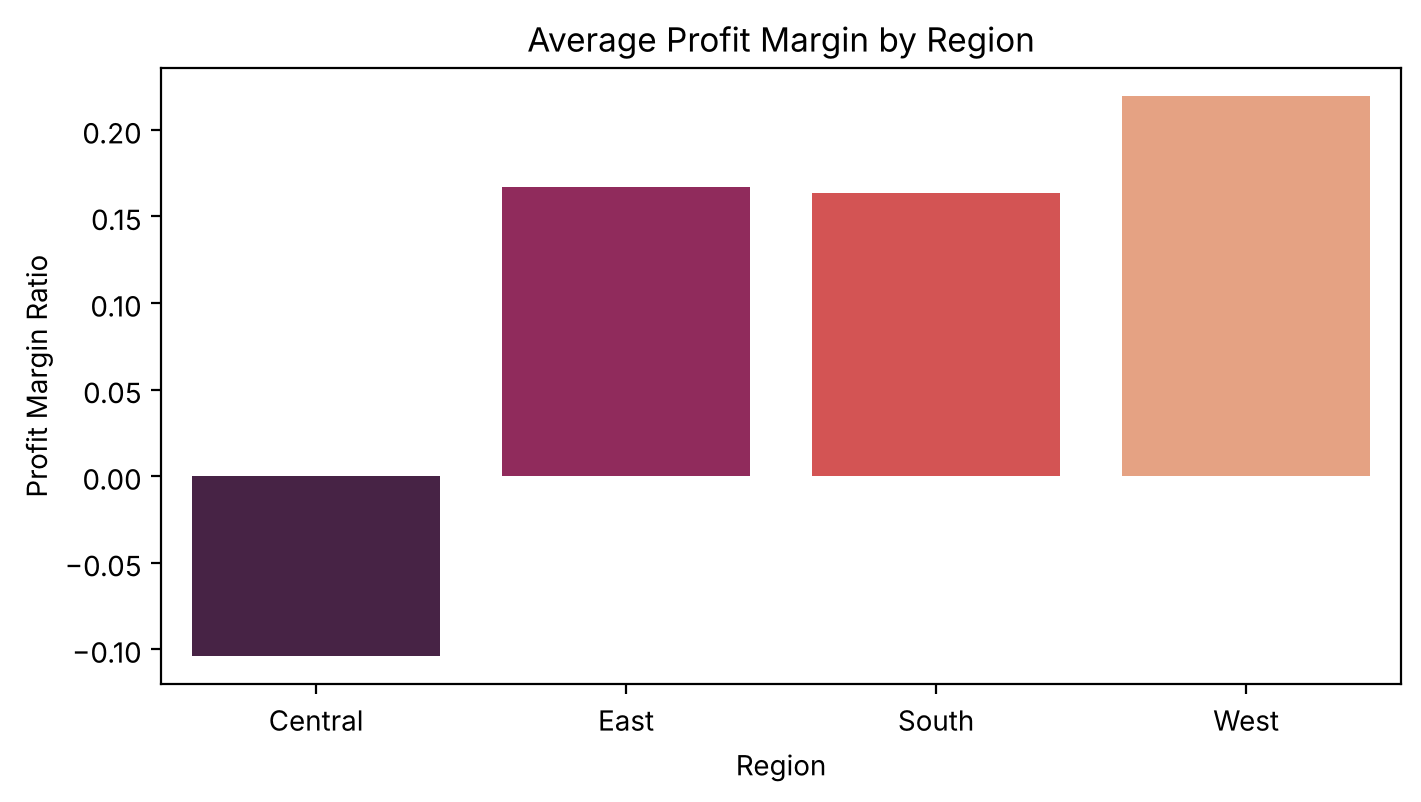

In [20]:
plt.figure(figsize=(8, 4))
region_margin = df_full.groupby("Region")["Profit Margin"].mean().reset_index()
sns.barplot(data=region_margin, x="Region", y="Profit Margin", palette="rocket")
plt.title("Average Profit Margin by Region")
plt.ylabel("Profit Margin Ratio")
plt.show()

**Key Insights:**
* **West** has the best average margin (≈ 22%), followed by **East** and **South** (≈ 16–17%).
* **Central** has a negative *average line-level* margin (≈ -10%) even though its total profit is positive (~$40K), so a few deeply discounted lines drag the average down. It is the region to review first.
